In [1]:
#Data and Features 
import pandas as pd
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor

model_df = pd.read_csv("../data/processed/model_table.csv",
                       parse_dates=["week"], dtype={"StockCode": str})

features = ["units_lag1", "units_lag2", "units_lag4",
            "units_mean4", "units_std4", "units_mean8", "units_std8",
            "orders_lag1", "orders4", "price_lag1", "price_change4",
            "trend_ratio", "week_of_year", "month", "weeks_to_xmas", "product_age"]

train = model_df[model_df["week"] <= "2011-05-30"]
val   = model_df[(model_df["week"] >= "2011-06-27") & (model_df["week"] <= "2011-08-08")]

X_train, y_train = train[features], train["target"]
X_val,   y_val   = val[features],   val["target"]

def evaluate(y_true, y_pred):
    err = y_pred - y_true
    return {"MAE": round(np.abs(err).mean(), 2),
            "RMSE": round(np.sqrt((err ** 2).mean()), 2),
            "WAPE": round(np.abs(err).sum() / y_true.sum(), 3)}

In [2]:
#Train models 
models = {
    "Linear Regression": make_pipeline(StandardScaler(), LinearRegression()),
    "Ridge": make_pipeline(StandardScaler(), Ridge(alpha=10)),
    "Random Forest": RandomForestRegressor(n_estimators=100, min_samples_leaf=5,
                                           n_jobs=-1, random_state=42),
    "Gradient Boosting": HistGradientBoostingRegressor(random_state=42),
}

results = {}
for name, m in models.items():
    m.fit(X_train, y_train)
    results[name] = evaluate(y_val, m.predict(X_val))

pd.DataFrame(results).T

,MAE,RMSE,WAPE
Linear Regression,48.23,149.04,0.578
Ridge,48.21,149.04,0.578
Random Forest,55.84,158.02,0.670
Gradient Boosting,49.77,156.35,0.597


A simple moving average is a strong baseline for intermittent demand. ML models reduce large errors (lower RMSE) but do not beat it on MAE

In [3]:
print(X_train.shape, X_val.shape)

(257466, 16) (29780, 16)


In [4]:
# Try 1: MAE-based loss
gb_mae = HistGradientBoostingRegressor(loss="absolute_error", random_state=42)
gb_mae.fit(X_train, y_train)
print(evaluate(y_val, gb_mae.predict(X_val)))

{'MAE': np.float64(40.67), 'RMSE': np.float64(151.39), 'WAPE': np.float64(0.488)}


In [6]:
# Try 2: log target
gb_log = HistGradientBoostingRegressor(random_state=42)
gb_log.fit(X_train, np.log1p(y_train))
pred = np.expm1(gb_log.predict(X_val)).clip(min=0)
print(evaluate(y_val, pred))

{'MAE': np.float64(41.54), 'RMSE': np.float64(155.72), 'WAPE': np.float64(0.498)}


In [7]:
from sklearn.model_selection import TimeSeriesSplit, RandomizedSearchCV

order = train["week"].argsort(kind="stable")
X_tr = X_train.iloc[order]
y_tr = y_train.iloc[order]
print(train["week"].iloc[order].is_monotonic_increasing)

True


In [8]:
# Start Tuning 
param_dist = {
    "learning_rate": [0.03, 0.05, 0.1],
    "max_iter": [200, 400],
    "max_leaf_nodes": [15, 31, 63],
    "min_samples_leaf": [20, 50, 100],
    "l2_regularization": [0.0, 1.0, 10.0],
}

search = RandomizedSearchCV(
    HistGradientBoostingRegressor(loss="absolute_error", random_state=42),
    param_dist, n_iter=12, cv=TimeSeriesSplit(n_splits=3),
    scoring="neg_mean_absolute_error", random_state=42, n_jobs=-1)

search.fit(X_tr, y_tr)
print(search.best_params_)
print("CV MAE:", -search.best_score_)

{'min_samples_leaf': 50, 'max_leaf_nodes': 15, 'max_iter': 200, 'learning_rate': 0.03, 'l2_regularization': 10.0}
CV MAE: 58.23081163191088


In [9]:
# Check the validation on the best model 
best = search.best_estimator_
print(evaluate(y_val, best.predict(X_val)))

{'MAE': np.float64(40.57), 'RMSE': np.float64(151.89), 'WAPE': np.float64(0.487)}


In [10]:
# Final Model
test = model_df[model_df["week"] >= "2011-09-05"]
X_test, y_test = test[features], test["target"]

test_results = {
    "Naive (4 x lag1)": evaluate(y_test, 4 * test["units_lag1"]),
    "Moving avg (4 x mean4)": evaluate(y_test, 4 * test["units_mean4"]),
    "Linear Regression": evaluate(y_test, models["Linear Regression"].predict(X_test)),
    "Ridge": evaluate(y_test, models["Ridge"].predict(X_test)),
    "Random Forest": evaluate(y_test, models["Random Forest"].predict(X_test)),
    "GB squared loss": evaluate(y_test, models["Gradient Boosting"].predict(X_test)),
    "GB absolute-error (tuned)": evaluate(y_test, best.predict(X_test)),
}
pd.DataFrame(test_results).T

,MAE,RMSE,WAPE
Naive (4 x lag1),84.93,332.80,0.672
Moving avg (4 x mean4),66.79,240.40,0.529
Linear Regression,65.78,238.31,0.521
Ridge,65.77,238.31,0.520
Random Forest,69.01,229.93,0.546
GB squared loss,67.69,237.10,0.536
GB absolute-error (tuned),60.51,246.93,0.479


In [11]:
# Error Analysis 
results = test[["StockCode", "week", "target"]].copy()
results["pred"] = best.predict(X_test).clip(min=0)
results["error"] = results["pred"] - results["target"]
results["abs_error"] = results["error"].abs()
results["last4_avg"] = test["units_mean4"] * 4
results["age"] = test["product_age"]

worst = results.sort_values("abs_error", ascending=False).head(10)
worst

,StockCode,week,target,pred,error,abs_error,last4_avg,age
183372,23084,2011-10-24,15190.0,219.038983,-14970.961017,14970.961017,448.0,24
183374,23084,2011-11-07,13728.0,1942.810062,-11785.189938,11785.189938,8282.0,26
183371,23084,2011-10-17,10925.0,361.629473,-10563.370527,10563.370527,469.0,23
129849,22197,2011-11-07,13275.0,2913.310975,-10361.689025,10361.689025,5979.0,100
183373,23084,2011-10-31,11940.0,1755.888229,-10184.111771,10184.111771,5983.0,25
129848,22197,2011-10-31,11156.0,2669.725906,-8486.274094,8486.274094,5658.0,99
129847,22197,2011-10-24,10976.0,2650.271132,-8325.728868,8325.728868,4558.0,98
183370,23084,2011-10-10,8282.0,568.645706,-7713.354294,7713.354294,479.0,22
129846,22197,2011-10-17,8995.0,2660.582839,-6334.417161,6334.417161,4076.0,97
247945,84077,2011-10-24,8639.0,2429.087116,-6209.912884,6209.912884,3702.0,98


In [12]:
# 1. Kitni total error top 1% rows se aati hai
top1 = results.nlargest(int(len(results) * 0.01), "abs_error")["abs_error"].sum()
print("Share of total error from top 1% rows:", round(top1 / results["abs_error"].sum(), 3))

# 2. Error by week
print(results.groupby("week")["abs_error"].mean().round(1))

# 3. Under vs over prediction
print("Under-predicted:", (results["error"] < 0).mean().round(3))

Share of total error from top 1% rows: 0.273
week
2011-09-05    57.3
2011-09-12    62.5
2011-09-19    60.0
2011-09-26    56.2
2011-10-03    59.8
2011-10-10    56.9
2011-10-17    64.0
2011-10-24    65.8
2011-10-31    62.9
2011-11-07    59.6
Name: abs_error, dtype: float64
Under-predicted: 0.343


In [13]:
# Product names
desc = (pd.read_csv("../data/processed/clean_transactions.csv", dtype={"StockCode": str})
          .drop_duplicates("StockCode").set_index("StockCode")["Description"])
for code in ["23084", "22197", "84077"]:
    print(code, "->", desc.get(code))

23084 -> RABBIT NIGHT LIGHT
22197 -> POPCORN HOLDER , SMALL 
84077 -> WORLD WAR 2 GLIDERS ASSTD DESIGNS


In [14]:
# Over-predictions (model predicted too much)
over = results.sort_values("error", ascending=False).head(5)
over

,StockCode,week,target,pred,error,abs_error,last4_avg,age
112564,21977,2011-10-10,644.0,2103.900200,1459.900200,1459.900200,2282.0,96
52356,21181,2011-10-31,301.0,1705.472728,1404.472728,1404.472728,1949.0,99
125389,22147,2011-10-17,87.0,1341.180827,1254.180827,1254.180827,2489.0,97
179820,22950,2011-10-24,127.0,1263.645505,1136.645505,1136.645505,1042.0,58
179821,22950,2011-10-31,23.0,1112.116393,1089.116393,1089.116393,973.0,59


<Axes: title={'center': 'Product 23084 weekly units'}, xlabel='week'>

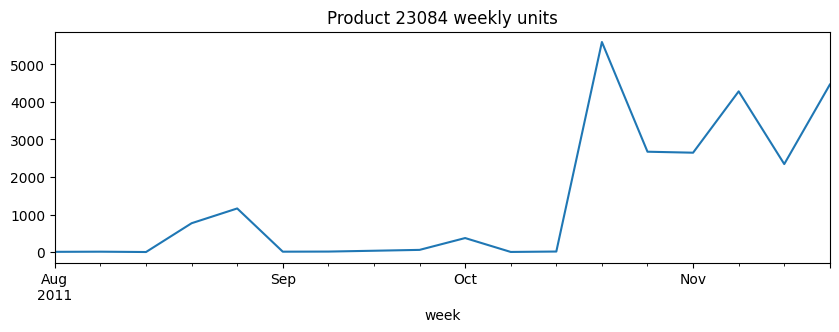

In [15]:
# Weekly plot of product 23084 (Figure 7)
panel = pd.read_csv("../data/processed/weekly_panel.csv", parse_dates=["week"], dtype={"StockCode": str})
p = panel[panel["StockCode"] == "23084"].set_index("week")["units"]
p["2011-08-01":].plot(figsize=(10, 3), title="Product 23084 weekly units")

<Axes: title={'center': 'Permutation importance (increase in MAE)'}>

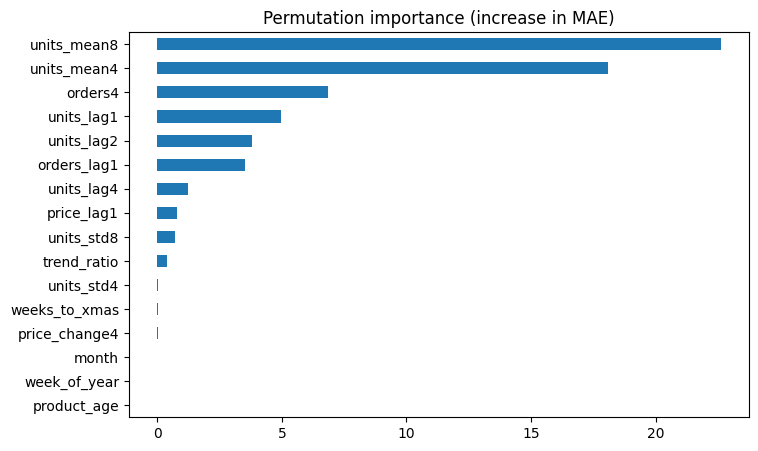

In [16]:
#Feature Importance 
from sklearn.inspection import permutation_importance

r = permutation_importance(best, X_val, y_val, scoring="neg_mean_absolute_error",
                           n_repeats=5, random_state=42, n_jobs=-1)
imp = pd.Series(r.importances_mean, index=features).sort_values()
imp.plot(kind="barh", figsize=(8, 5), title="Permutation importance (increase in MAE)")

In [17]:
# Save the model 
import joblib
joblib.dump(best, "../models/gb_model.joblib")
model_df.to_csv("../data/processed/model_table.csv", index=False)

In [18]:
resid = (y_val - best.predict(X_val))
safety = resid.quantile(0.80)   # covers 80% of cases
print(safety)

13.949080353571073
